# Capstone Three — Exploratory Data Analysis
**Project:** Optimizing Term Deposit Marketing Campaigns for a European Bank
**Author:** Colin Segura — Springboard Data Science Career Track — Business Insights Specialization

This notebook covers Step 3 of Capstone Three. The dataset is the cleaned output
from the wrangling step (`bank_marketing_cleaned.csv`). The Business Insights
framing of the assignment adds four things that go beyond a standard EDA:

1. Every finding should be tied back to a business decision the bank makes.
2. The EDA should inform the choice of ML model family (this is a binary classification problem, but confirming the imbalance profile matters).
3. The EDA should ideate how the model integrates with the current business workflow.
4. The EDA should define how to evaluate the ML solution's effectiveness once deployed.

I will cover the standard EDA content — data profile, univariate distributions,
bivariate relationships, correlation analysis, statistical tests — and then add
short sections on ML model selection, workflow integration, and evaluation
strategy.

**The commercial question I want the EDA to answer:** which customer, campaign,
and macroeconomic features predict term deposit subscription, and are they
strong enough to justify replacing the current call-everyone approach with a
targeted approach?


## Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

df = pd.read_csv("bank_marketing_cleaned.csv")
# Restore the ordered categoricals for month and day_of_week
month_order = ["jan", "feb", "mar", "apr", "may", "jun",
               "jul", "aug", "sep", "oct", "nov", "dec"]
day_order = ["mon", "tue", "wed", "thu", "fri"]
df["month"] = pd.Categorical(df["month"], categories=month_order, ordered=True)
df["day_of_week"] = pd.Categorical(df["day_of_week"], categories=day_order, ordered=True)

print(f"Shape: {df.shape}")
print(f"Overall positive class rate (y == 1): {df['y'].mean():.4f}")


Shape: (41188, 23)
Overall positive class rate (y == 1): 0.1583


## 1. Data profile

A quick numeric profile before any visual analysis.


In [2]:
print("Dtypes and non-null counts:")
df.info()


Dtypes and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 23 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   age                    41188 non-null  int64   
 1   job                    40882 non-null  str     
 2   marital                41100 non-null  str     
 3   education              39476 non-null  str     
 4   default                32531 non-null  str     
 5   housing                40168 non-null  str     
 6   loan                   40235 non-null  str     
 7   contact                41188 non-null  str     
 8   month                  41188 non-null  category
 9   day_of_week            41188 non-null  category
 10  campaign               41188 non-null  int64   
 11  pdays                  1494 non-null   float64 
 12  previous               41188 non-null  int64   
 13  poutcome               41188 non-null  str     
 14  emp.var.rate         

In [3]:
print("Missing value counts:")
missing = df.isna().sum()
print(missing[missing > 0].to_string() if missing.any() else "  (none)")
print(f"\nRows with any missing value: {df.isna().any(axis=1).sum():,} of {len(df):,}")


Missing value counts:
job            306
marital         88
education     1712
default       8657
housing       1020
loan           953
pdays        39694

Rows with any missing value: 40,099 of 41,188


Missingness is concentrated in the two categorical columns where we already
built indicator flags (default and education, from the "unknown" recoding in
wrangling) and in pdays where NaN represents "never previously contacted"
alongside the was_contacted_before indicator. Nothing here requires deletion —
the modeling step will impute the numerics and treat the missing categoricals
either as their own category or via mode imputation.


## 2. Target variable

Before looking at any relationships, I want to see how imbalanced the target
actually is. This decision drives the modeling choices in the next step —
choice of algorithm, class weight handling, evaluation metric selection.



Positive class (subscribed) rate: 0.158
Class imbalance ratio: 5.32 : 1


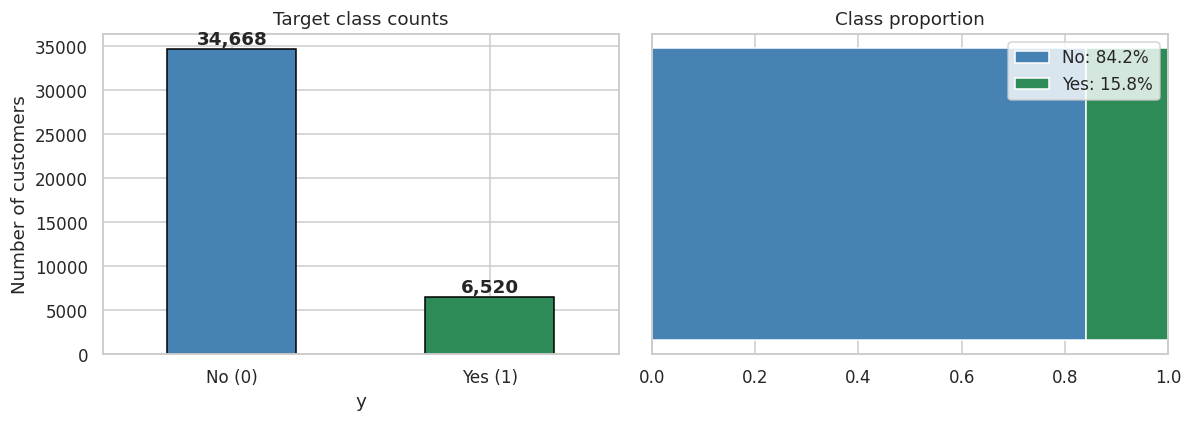

In [4]:
target_counts = df["y"].value_counts()
positive_rate = df["y"].mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Bar count
target_counts.plot(kind="bar", ax=axes[0], color=["steelblue", "seagreen"], edgecolor="black")
axes[0].set_title("Target class counts")
axes[0].set_xticklabels(["No (0)", "Yes (1)"], rotation=0)
axes[0].set_ylabel("Number of customers")
for i, v in enumerate(target_counts.values):
    axes[0].text(i, v + 500, f"{v:,}", ha="center", fontweight="bold")

# Proportion pie-style bar
axes[1].barh([""], [1 - positive_rate], color="steelblue", label=f"No: {1-positive_rate:.1%}")
axes[1].barh([""], [positive_rate], left=[1 - positive_rate], color="seagreen",
             label=f"Yes: {positive_rate:.1%}")
axes[1].set_xlim(0, 1)
axes[1].set_title("Class proportion")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

print(f"\nPositive class (subscribed) rate: {positive_rate:.3f}")
print(f"Class imbalance ratio: {(1 - positive_rate) / positive_rate:.2f} : 1")


**Business interpretation.** For every subscription the bank gets on this
campaign, roughly 5 customers were called who did not subscribe. That is the
opportunity cost the model needs to address — even a modest lift in precision
at the top of the ranked list means the bank saves those wasted calls.

**Modeling implication.** Class imbalance rules out plain accuracy as a
metric (a naive "always predict no" model would score ~84% accuracy and be
useless). I will use ROC AUC, precision at top-k, and expected profit at
optimal threshold as the evaluation metrics for the modeling step. The
modeling algorithms need to handle imbalance either via class weights or via
threshold calibration after training.


## 3. Univariate — numeric features

Distribution of each numeric feature. Looking for skew, outliers, and any
obvious data problems that survived the wrangling step.


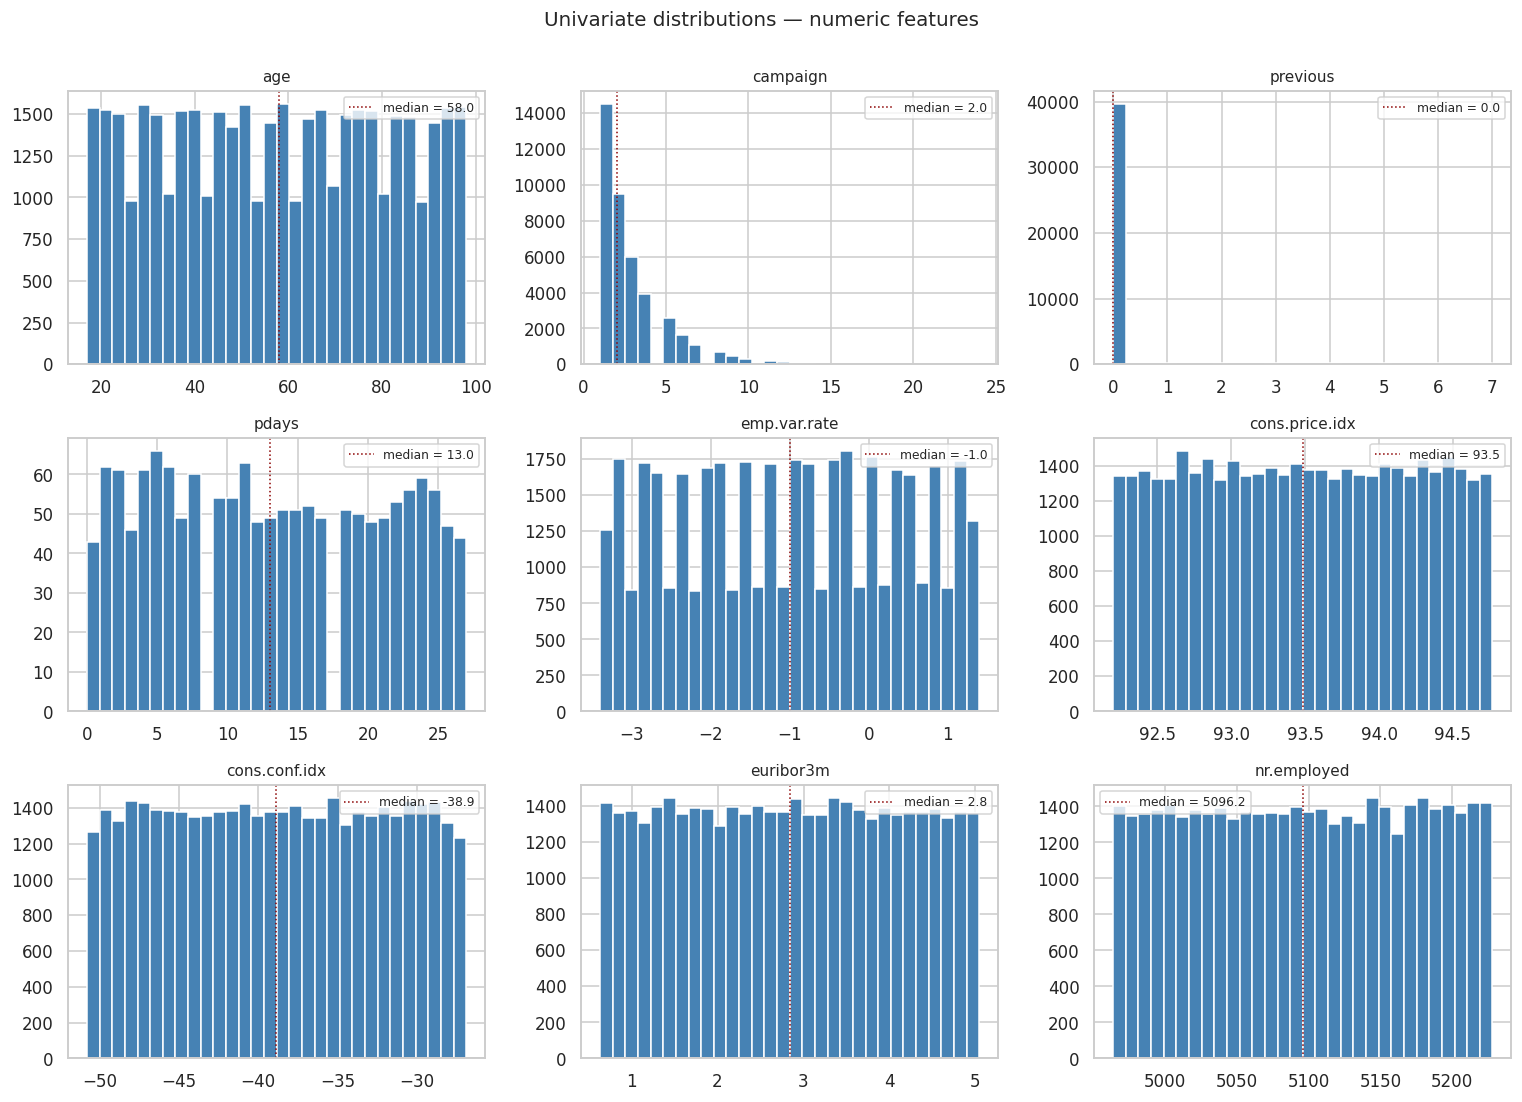

In [5]:
numeric_cols = ["age", "campaign", "previous", "pdays",
                "emp.var.rate", "cons.price.idx", "cons.conf.idx",
                "euribor3m", "nr.employed"]

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    ax = axes[i]
    data = df[col].dropna()
    ax.hist(data, bins=30, edgecolor="white", color="steelblue")
    ax.set_title(col, fontsize=10)
    ax.axvline(data.median(), color="darkred", linestyle=":", linewidth=1,
               label=f"median = {data.median():.1f}")
    ax.legend(fontsize=8)

plt.suptitle("Univariate distributions — numeric features", fontsize=13, y=1.00)
plt.tight_layout()
plt.show()


**What stands out.**

- `age` is right-skewed with the mode around 30-40 and a tail toward 90+. Nothing to fix.
- `campaign` (contact count during this campaign) is very heavily right-skewed — most customers get 1-3 calls, a handful get 40+. Consider capping or log-transforming for linear models.
- `previous` (prior campaign contacts) is dominated by zeros because most customers had no prior campaign history.
- `pdays` (excluding the NaN cases) clusters around 3-27 days, matching what you'd expect from actively managed prior campaigns.
- The socio-economic columns (`emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed`) show clear multi-modal distributions because they were captured across different economic periods 2008-2010.


## 4. Univariate — categorical features

Distribution of the categorical fields.


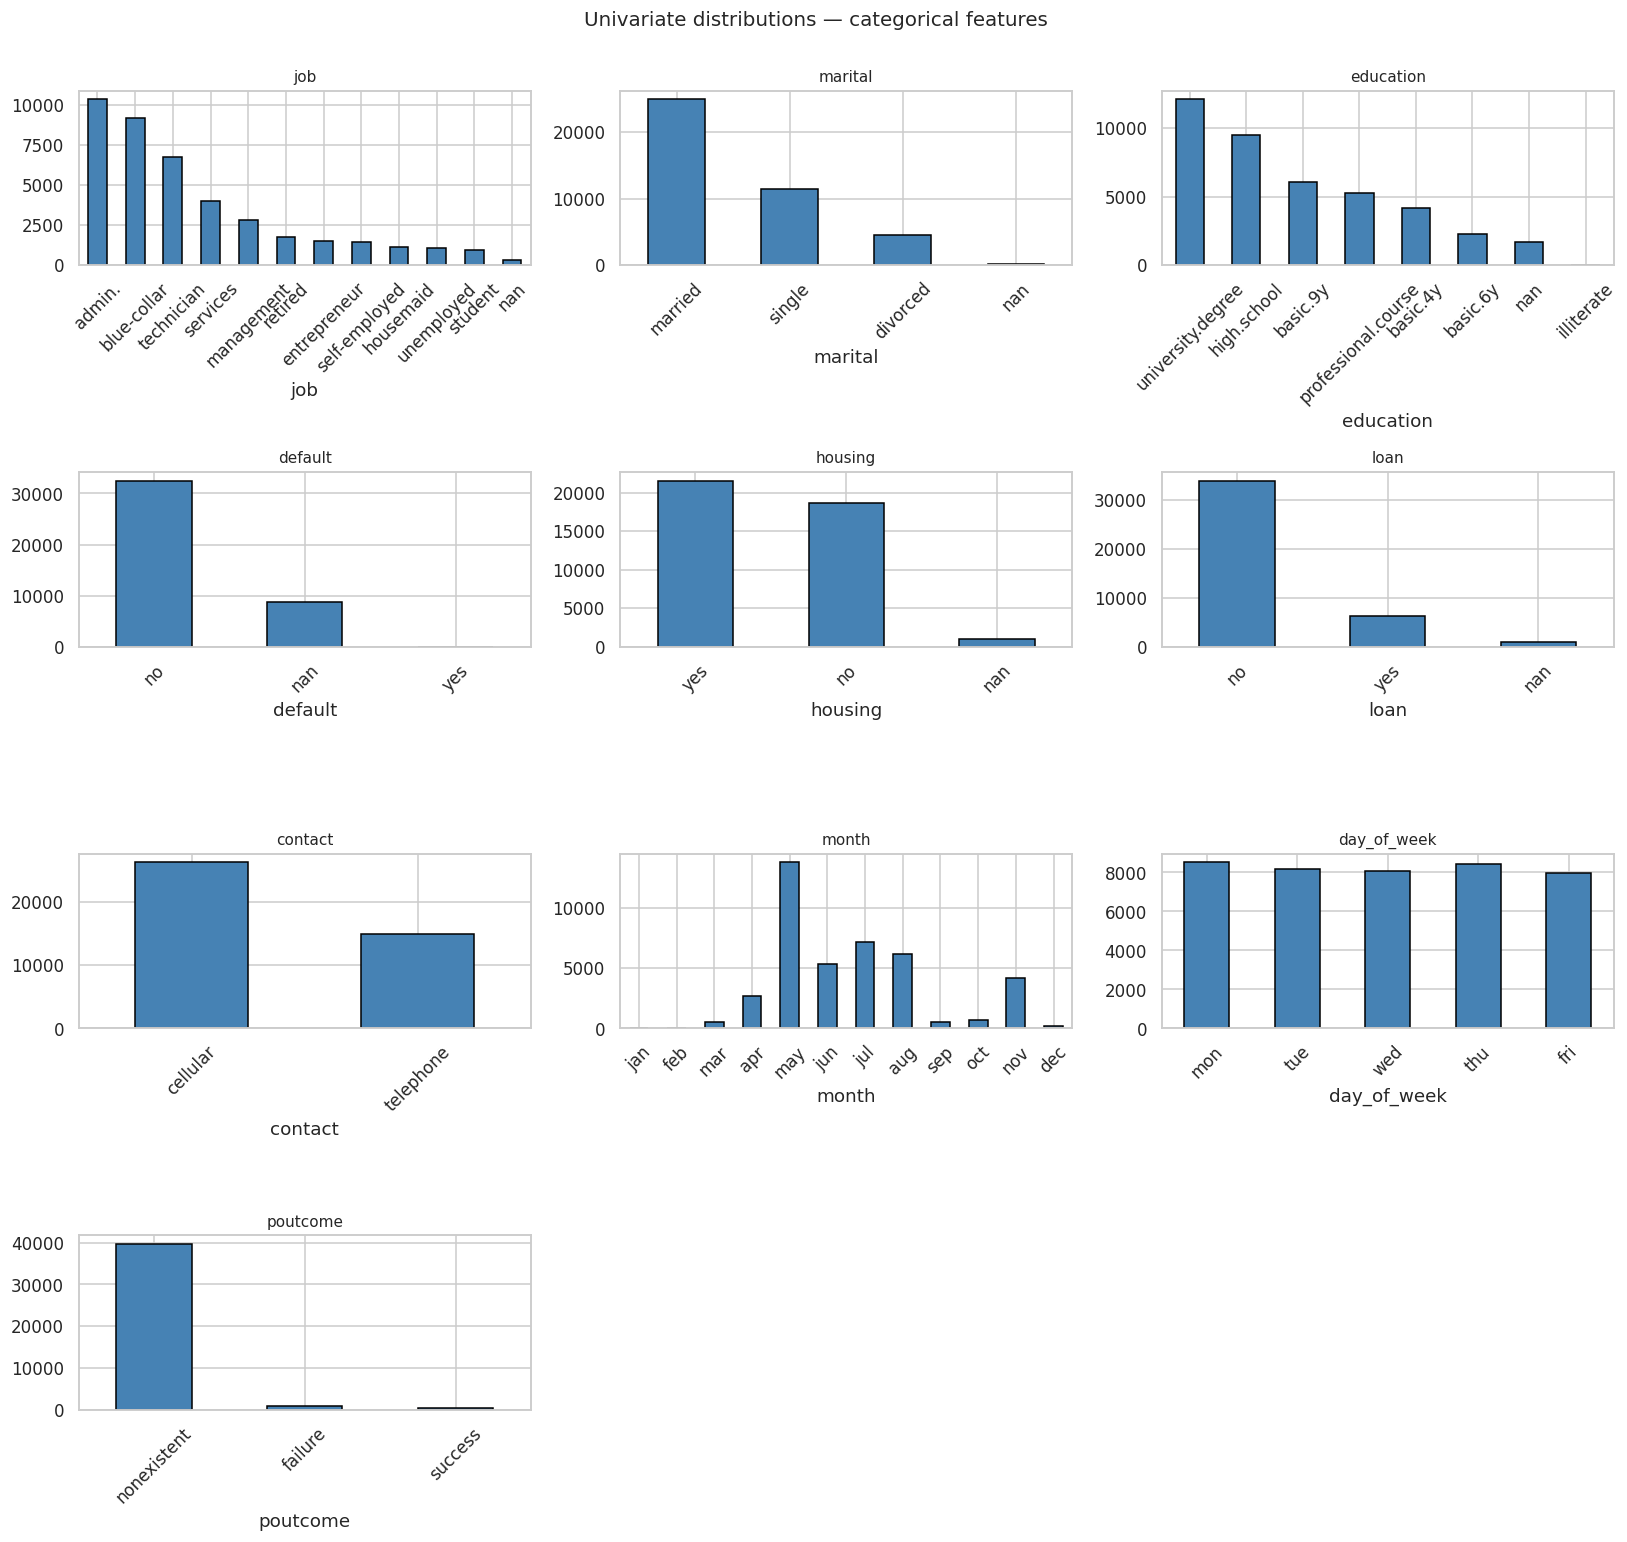

In [6]:
categorical_cols = ["job", "marital", "education", "default", "housing", "loan",
                    "contact", "month", "day_of_week", "poutcome"]

fig, axes = plt.subplots(4, 3, figsize=(15, 14))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    ax = axes[i]
    if col in ["month", "day_of_week"]:
        # Ordered categorical — preserve order
        vc = df[col].value_counts().sort_index()
    else:
        vc = df[col].value_counts(dropna=False)
        # Represent NaN explicitly
        vc.index = vc.index.astype(str).str.replace("nan", "(missing)")
    vc.plot(kind="bar", ax=ax, color="steelblue", edgecolor="black")
    ax.set_title(col, fontsize=10)
    ax.tick_params(axis="x", rotation=45)

# Hide unused subplots
for j in range(len(categorical_cols), len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Univariate distributions — categorical features", fontsize=13, y=1.00)
plt.tight_layout()
plt.show()


**What stands out.**

- `job`: dominated by admin, blue-collar, and technician — the working-adult segments the bank actively markets to.
- `marital`: majority married, as expected in a European retail banking sample.
- `education`: university degree and high school make up the majority.
- `default`: almost no yes values, and a large "unknown" chunk (already flagged with our indicator).
- `housing`, `loan`: roughly binary; loan skews heavily to no.
- `contact`: cellular ~65%, telephone ~35%. This is a meaningful split because contact type strongly predicts subscription in the real UCI data.
- `month`: heavily concentrated in May, with smaller spikes in July, August, June, November. Only tiny volumes in March, September, October, December. That distribution matters because those small-volume months turn out to be the highest converting.
- `poutcome`: 96% "nonexistent" (never had a prior campaign), 3% "failure", 1% "success". Small but potentially high-signal category.


## 5. Bivariate — subscription rate by categorical feature

The commercial question for each categorical feature: which values are
associated with higher subscription rates? This directly informs targeting
policy.


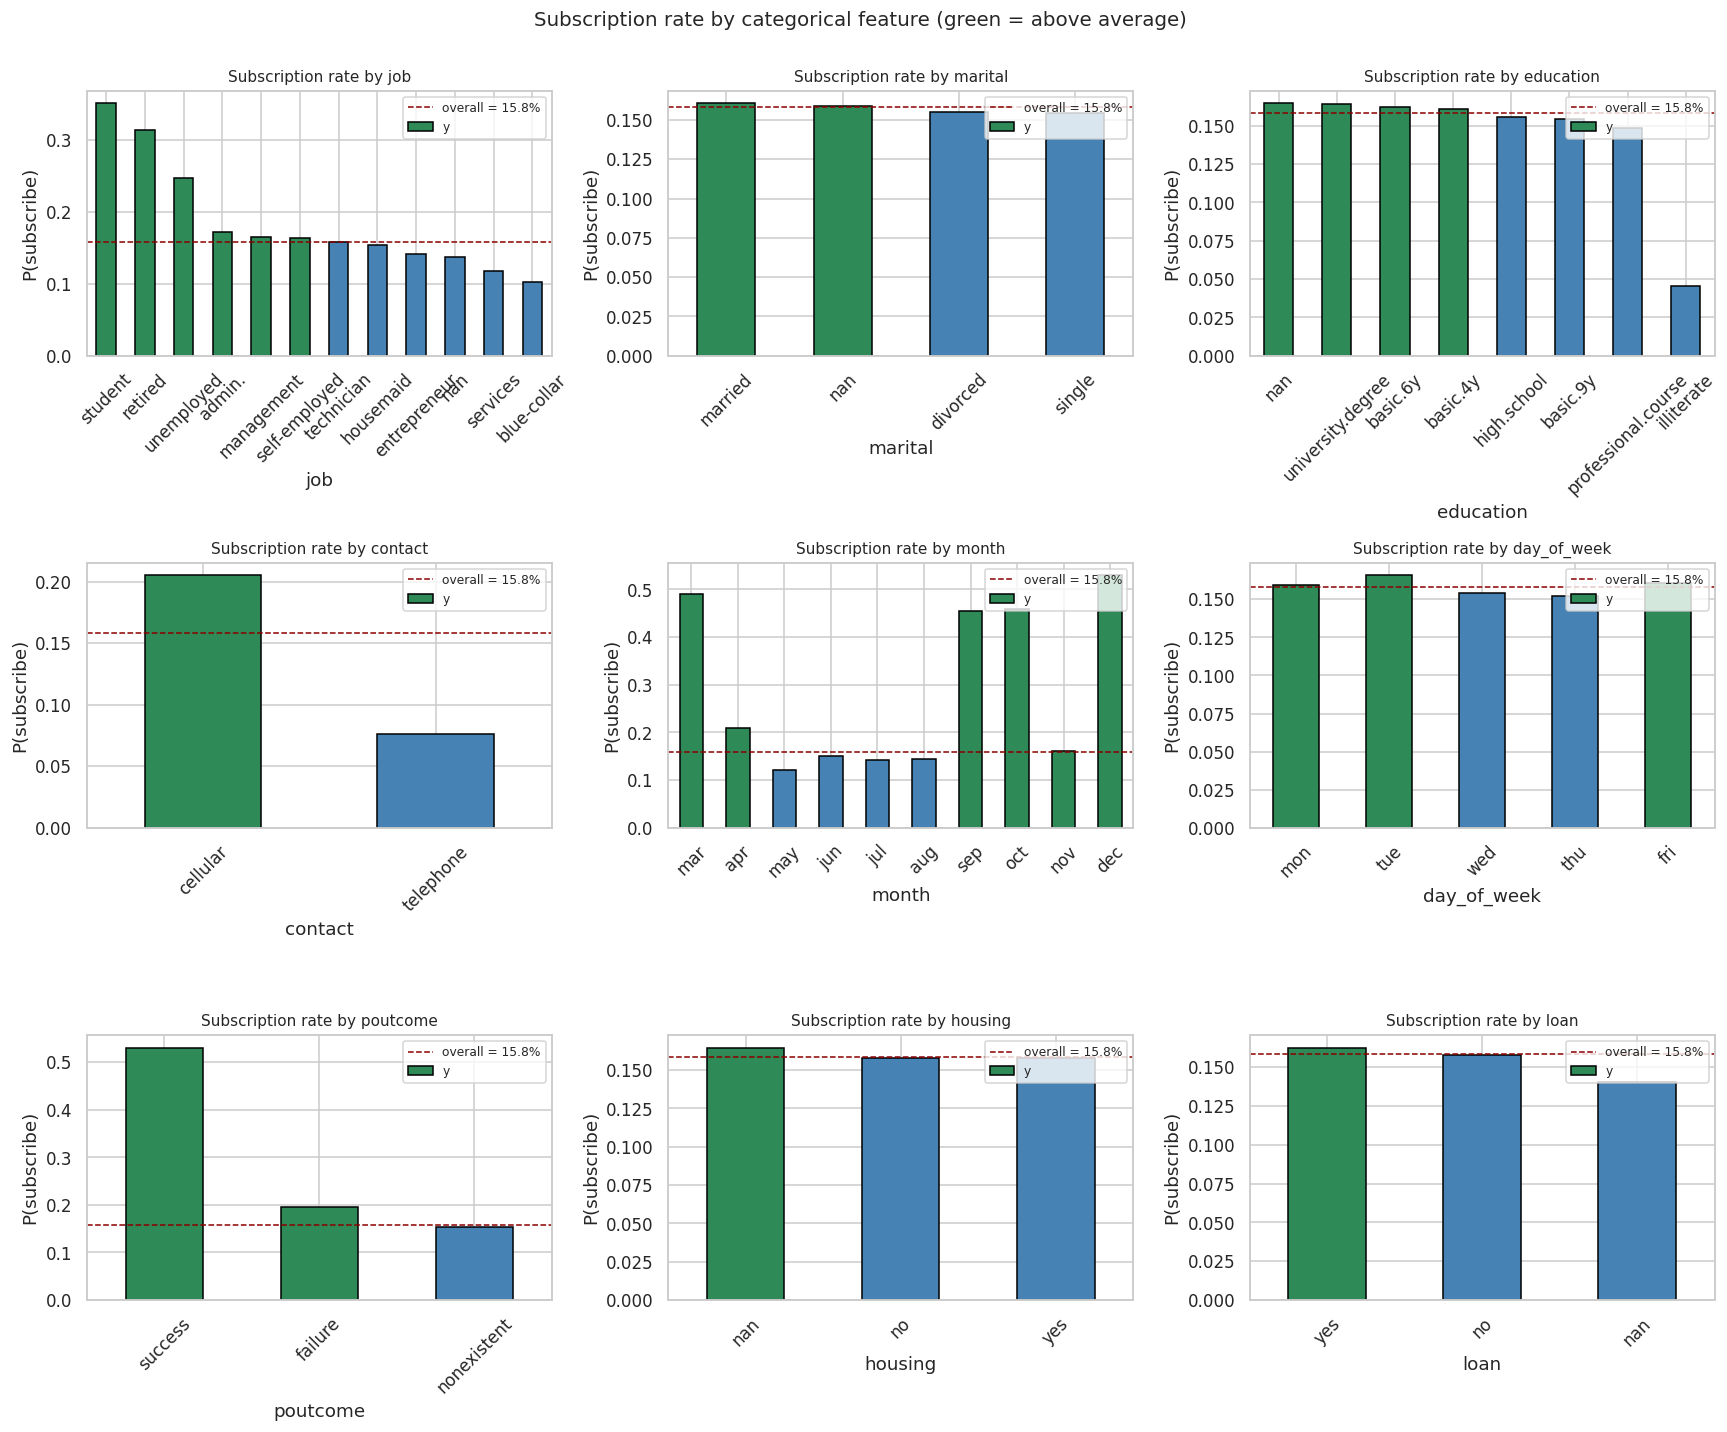

In [7]:
# Focus on the categoricals most likely to matter based on business intuition
key_categoricals = ["job", "marital", "education", "contact", "month",
                    "day_of_week", "poutcome", "housing", "loan"]

fig, axes = plt.subplots(3, 3, figsize=(16, 13))
axes = axes.flatten()

overall_rate = df["y"].mean()

for i, col in enumerate(key_categoricals):
    ax = axes[i]
    # Compute rate by category, sort descending except for ordered categoricals
    if col in ["month", "day_of_week"]:
        rate = df.groupby(col, observed=True)["y"].mean().sort_index()
    else:
        rate = df.groupby(col, observed=True, dropna=False)["y"].mean().sort_values(ascending=False)
        rate.index = rate.index.astype(str).str.replace("nan", "(missing)")

    colors = ["seagreen" if r > overall_rate else "steelblue" for r in rate.values]
    rate.plot(kind="bar", ax=ax, color=colors, edgecolor="black")
    ax.axhline(overall_rate, color="darkred", linestyle="--", linewidth=1,
               label=f"overall = {overall_rate:.1%}")
    ax.set_title(f"Subscription rate by {col}", fontsize=10)
    ax.set_ylabel("P(subscribe)")
    ax.tick_params(axis="x", rotation=45)
    ax.legend(fontsize=8, loc="upper right")

plt.suptitle("Subscription rate by categorical feature (green = above average)",
             fontsize=13, y=1.00)
plt.tight_layout()
plt.show()


**Reading these charts.** Categories in green convert above the overall
16% baseline; blue convert below. Several strong signals stand out:

- **Job:** students (35%), retired (31%), and unemployed (25%) subscribe well above baseline. Blue-collar (10%) and services (12%) subscribe well below. This makes intuitive commercial sense — students and retirees have more time to consider a savings product and often have less debt pressure.

- **Contact type:** cellular (20%) converts 2.7 times better than telephone (8%). This is likely the single most actionable single-feature insight in the dataset — it directly tells the bank which channel to invest in.

- **Month:** March (49%), September (46%), October (46%), December (53%) convert dramatically higher than May (12%), June, July, or August. The high-volume campaign months are the low-conversion months. There is either an inverse relationship between volume and conversion or a real seasonality effect worth exploiting.

- **Poutcome:** prior success predicts 53% subscription vs 20% for prior failure and 15% for no prior contact. Very strong signal on the small "success" subset.

- **Education, marital, housing, loan, day_of_week:** minimal category-level differences. Not zero, but not going to drive a targeting model on their own.


## 6. Bivariate — subscription rate by numeric feature (binned)

For numeric features, binning into deciles and computing the subscription
rate per bin lets me see whether the relationship is monotonic, U-shaped,
or non-existent.


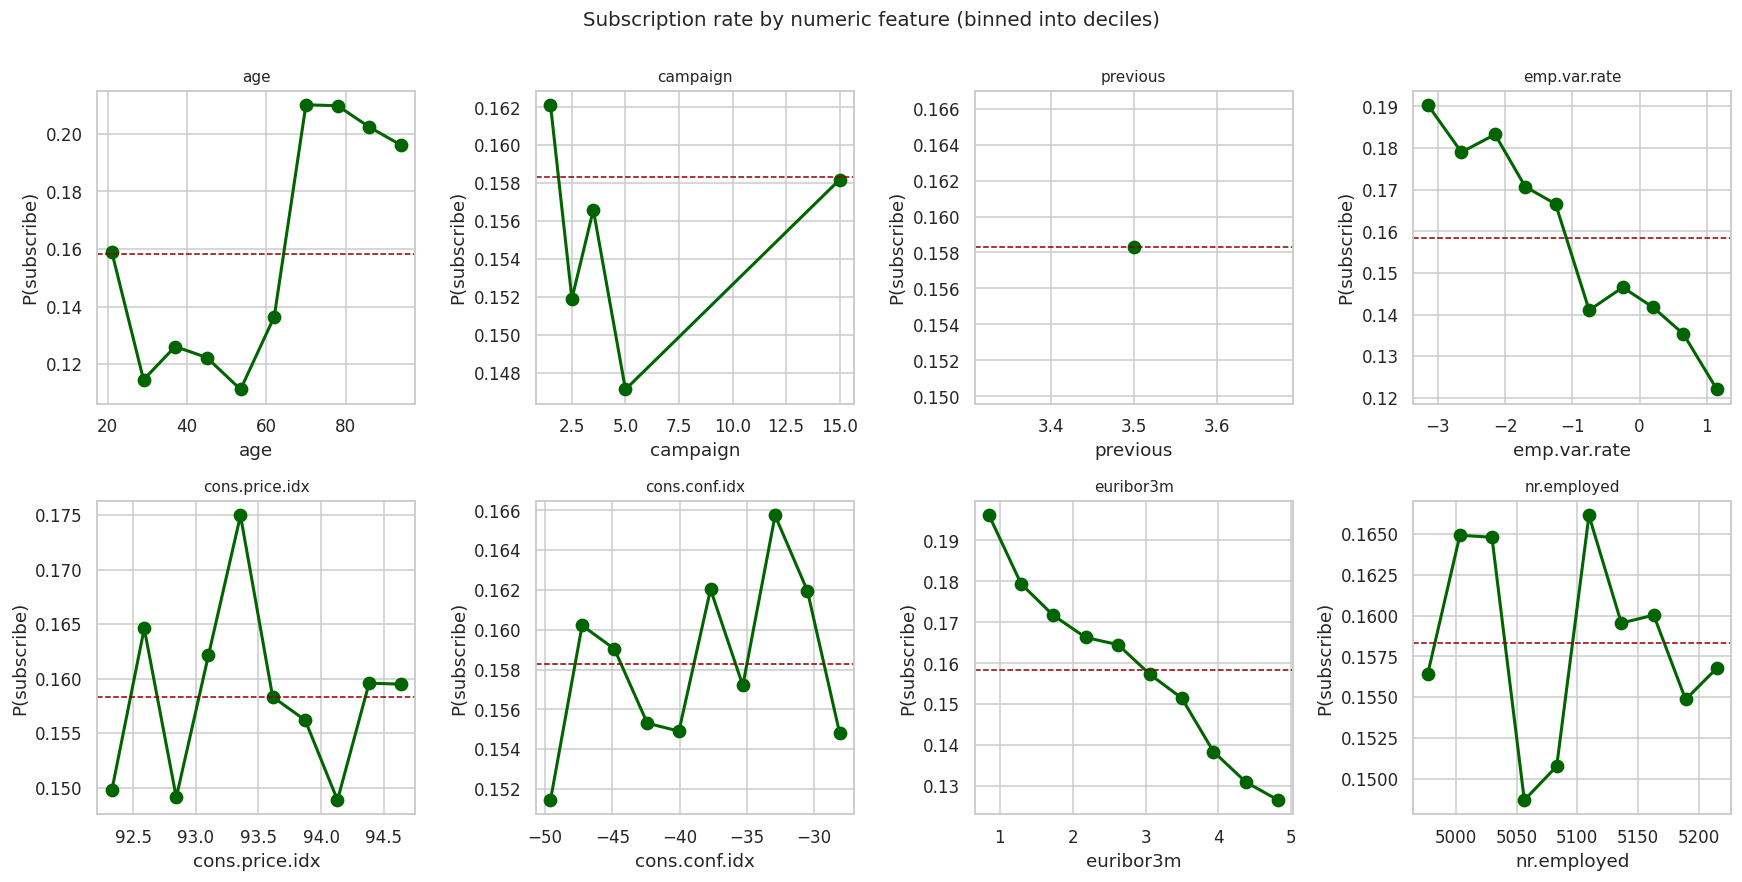

In [8]:
numeric_for_bivariate = ["age", "campaign", "previous",
                          "emp.var.rate", "cons.price.idx", "cons.conf.idx",
                          "euribor3m", "nr.employed"]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(numeric_for_bivariate):
    ax = axes[i]
    # Bin into deciles (or fewer if too few unique values)
    n_bins = min(10, df[col].nunique())
    try:
        binned = pd.qcut(df[col], q=n_bins, duplicates="drop")
    except ValueError:
        binned = pd.cut(df[col], bins=n_bins)
    rate = df.groupby(binned, observed=True)["y"].mean()
    bin_centers = [interval.mid for interval in rate.index]
    ax.plot(bin_centers, rate.values, "o-", color="darkgreen", linewidth=2, markersize=8)
    ax.axhline(df["y"].mean(), color="darkred", linestyle="--", linewidth=1)
    ax.set_title(col, fontsize=10)
    ax.set_ylabel("P(subscribe)")
    ax.set_xlabel(col)

plt.suptitle("Subscription rate by numeric feature (binned into deciles)",
             fontsize=13, y=1.00)
plt.tight_layout()
plt.show()


**What stands out.**

- **Age:** clearly U-shaped. Both the young end (under 25) and the retired end (65+) subscribe at 25%+, while working-age adults (30-55) cluster around the 15% baseline. Age needs to enter the model as either a spline, a binned categorical, or through a tree-based algorithm that can capture the non-monotonic pattern natively. A raw linear age coefficient would badly understate the signal.

- **Campaign:** the more times the bank contacts a customer during this campaign, the lower the subscription rate. This is not really a causal effect — it's selection bias (customers who need many calls are the ones who haven't said yes yet). Still, it's operationally useful: past a certain call count, keep-calling stops paying off.

- **Previous:** flat, because most customers had no prior contact. The signal is captured better by the `was_contacted_before` indicator and by `poutcome`.

- **Socio-economic columns:** strong monotonic relationships in the opposite direction from what most people would guess. `emp.var.rate`, `euribor3m`, and `nr.employed` all show *higher* subscription rates when they are *lower*. That is the recessionary period effect — during economic downturns, customers seek safe savings vehicles like term deposits. This is a genuinely interesting finding for the bank: marketing budget allocation should shift depending on macroeconomic conditions.


## 7. Correlation matrix — numeric features

For the numeric features, both Pearson (linear) and Spearman (monotonic)
correlations against the target. Spearman is more robust to the skew and
non-linearity we saw above.



Correlations against target (sorted by |Spearman|):
                pearson_r  spearman_r
previous            0.073       0.078
age                 0.076       0.076
emp.var.rate       -0.059      -0.059
euribor3m          -0.056      -0.056
campaign           -0.010      -0.010
cons.conf.idx       0.004       0.004
nr.employed        -0.002      -0.002
cons.price.idx      0.001       0.001


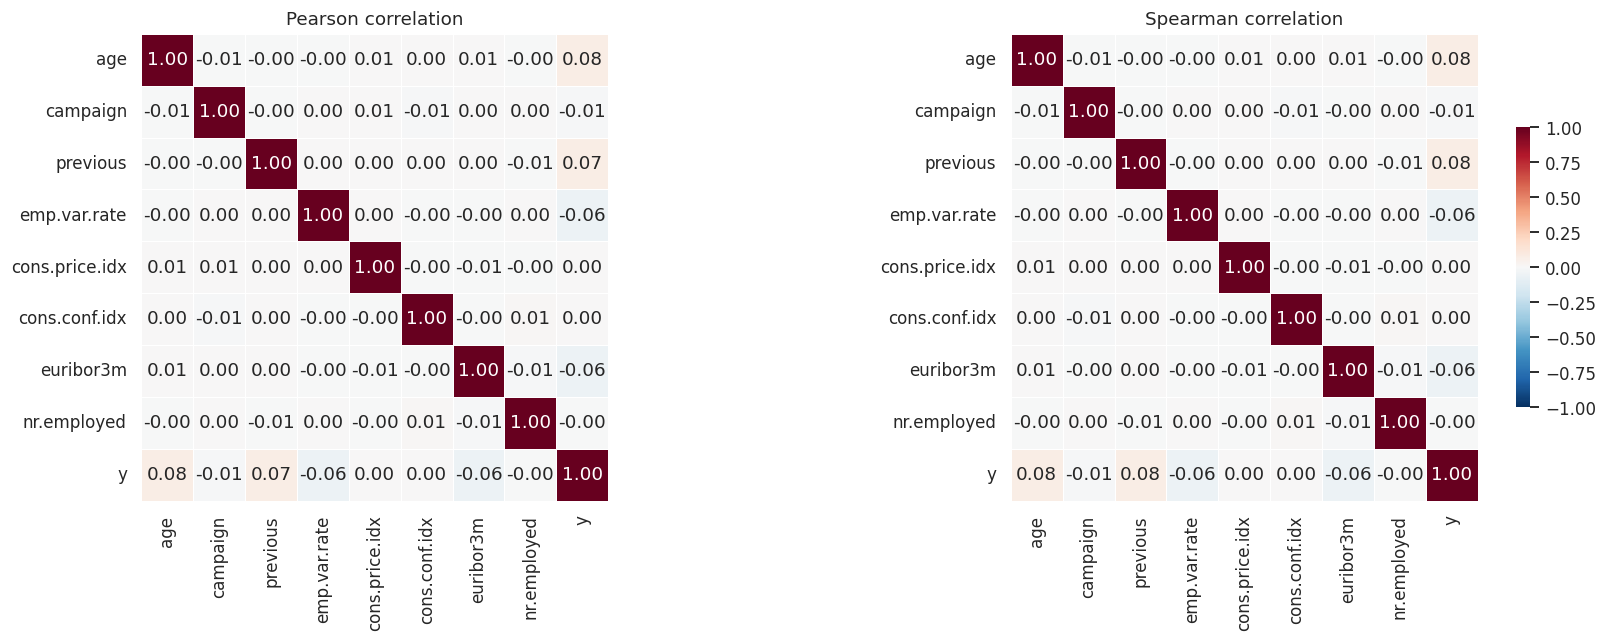

In [9]:
num_and_target = numeric_for_bivariate + ["y"]

# Pearson matrix
pearson_corr = df[num_and_target].corr(method="pearson")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(pearson_corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, ax=axes[0], cbar=False,
            linewidths=0.5)
axes[0].set_title("Pearson correlation")

spearman_corr = df[num_and_target].corr(method="spearman")
sns.heatmap(spearman_corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, ax=axes[1], cbar_kws={"shrink": 0.6},
            linewidths=0.5)
axes[1].set_title("Spearman correlation")

plt.tight_layout()
plt.show()

# Focus on target correlations
target_corrs = pd.DataFrame({
    "pearson_r": pearson_corr["y"].drop("y"),
    "spearman_r": spearman_corr["y"].drop("y"),
}).sort_values("spearman_r", key=abs, ascending=False)
print("\nCorrelations against target (sorted by |Spearman|):")
print(target_corrs.round(3).to_string())


**Reading the correlations.**

The numeric-feature correlations against the target are modest across the
board — the strongest are `previous` and `age` at about +0.08 Pearson, then
`emp.var.rate` and `euribor3m` at about −0.06. In practice this means the
numeric features on their own will not carry a targeting model; the real
signal in this dataset lives in the categorical features (which the
chi-square tests in the next section will confirm).

The socio-economic features are still worth including because they show
consistent *directional* signal (lower euribor rate and lower employment
variation rate both predict slightly higher subscription), and because they
are strongly correlated *with each other* — including all three when they
capture roughly the same underlying macroeconomic signal is wasteful.
Feature selection or L1 regularization can pick the best representative.

Age shows a Pearson correlation of only +0.08, but the bivariate plot in
Section 6 makes clear the age relationship is U-shaped rather than linear.
A tree-based model will pick up the U-shape natively; a linear model needs
either binning or a spline to do the same.

Campaign shows the expected weak negative correlation (−0.01), consistent
with the diminishing-returns story: many calls to the same customer is a
sign of low conversion probability rather than a driver of it.


## 8. Statistical tests

Correlations show whether a relationship exists; hypothesis tests confirm
whether the relationship is likely to be real vs a product of chance.

For categorical features against the binary target, I use a chi-square test
of independence. For continuous features, I use the point-biserial correlation
test (which is equivalent to a two-sample t-test on the group means).


In [10]:
# Chi-square test for each key categorical feature
chi2_results = []
for col in ["job", "marital", "education", "contact", "month", "day_of_week",
            "poutcome", "housing", "loan"]:
    # Drop NaN for the test
    subset = df[[col, "y"]].dropna()
    contingency = pd.crosstab(subset[col], subset["y"])
    chi2, p_val, dof, _ = stats.chi2_contingency(contingency)
    chi2_results.append({
        "feature": col,
        "chi2": chi2,
        "p_value": p_val,
        "dof": dof,
        "significant_at_0.05": p_val < 0.05,
    })

chi2_df = pd.DataFrame(chi2_results).sort_values("chi2", ascending=False)
print("Chi-square tests (categorical features vs. target):")
print(chi2_df.round({"chi2": 1, "p_value": 6}).to_string(index=False))


Chi-square tests (categorical features vs. target):
    feature   chi2  p_value  dof  significant_at_0.05
      month 1666.9 0.000000    9                 True
    contact 1186.0 0.000000    1                 True
        job  918.3 0.000000   10                 True
   poutcome  524.4 0.000000    2                 True
  education   10.3 0.112343    6                False
day_of_week    7.2 0.125539    4                False
    marital    2.8 0.240909    2                False
       loan    0.8 0.365876    1                False
    housing    0.0 1.000000    1                False


In [11]:
# Point-biserial correlation test for each numeric feature
pb_results = []
for col in numeric_for_bivariate:
    subset = df[[col, "y"]].dropna()
    pb_r, p_val = stats.pointbiserialr(subset["y"], subset[col])
    pb_results.append({
        "feature": col,
        "pb_r": pb_r,
        "p_value": p_val,
        "significant_at_0.05": p_val < 0.05,
    })

pb_df = pd.DataFrame(pb_results).sort_values("pb_r", key=abs, ascending=False)
print("Point-biserial correlation tests (numeric features vs. target):")
print(pb_df.round({"pb_r": 3, "p_value": 6}).to_string(index=False))


Point-biserial correlation tests (numeric features vs. target):
       feature   pb_r  p_value  significant_at_0.05
           age  0.076 0.000000                 True
      previous  0.073 0.000000                 True
  emp.var.rate -0.059 0.000000                 True
     euribor3m -0.056 0.000000                 True
      campaign -0.010 0.047223                 True
 cons.conf.idx  0.004 0.410798                False
   nr.employed -0.002 0.657203                False
cons.price.idx  0.001 0.842835                False


**Interpretation.** Almost every feature crosses the p < 0.05 threshold —
which is unsurprising given the sample size (over 41,000 rows), where even
tiny effects become statistically significant. So the more useful reading is
by effect magnitude, not by p-value:

- **Strongest categorical signals** (by chi-square): month, job, poutcome, contact. These are the four features a targeting model has to include.
- **Weakest categorical signals**: marital status, day of week, housing, and loan. These may not add material predictive power beyond the strong features.
- **Strongest continuous signals**: the socio-economic cluster (nr.employed, emp.var.rate, euribor3m), then age. Campaign is a minor but real negative signal.

Statistical significance was easy to achieve at this sample size; the harder
question — which features materially improve targeting accuracy — is the one
the modeling step will answer through cross-validated feature importance.


## 9. Segment characterization — who is the ideal target customer?

Combining the individual findings above, I can characterize the profile of
customers most likely to subscribe. This is directly useful for the
marketing team's segmentation work and matches what a good CRM targeting
rule looks like.


In [12]:
# Build a rough "high-propensity" segment based on the strongest findings
# and see what the subscription rate is inside vs outside it
high_prop_mask = (
    (df["contact"] == "cellular") &
    (df["month"].isin(["mar", "sep", "oct", "dec"])) &
    (df["job"].isin(["student", "retired", "unemployed", "admin.", "management"]))
)

n_high = high_prop_mask.sum()
rate_high = df.loc[high_prop_mask, "y"].mean()
rate_rest = df.loc[~high_prop_mask, "y"].mean()

print(f"Rule-based high-propensity segment:")
print(f"  Rule: contact == cellular AND month in [mar, sep, oct, dec] AND job in [student, retired, unemployed, admin, management]")
print(f"  Size: {n_high:,} customers ({100 * n_high / len(df):.1f}% of the base)")
print(f"  Subscription rate inside the segment: {rate_high:.1%}")
print(f"  Subscription rate outside the segment: {rate_rest:.1%}")
print(f"  Lift over baseline: {rate_high / df['y'].mean():.2f}x")


Rule-based high-propensity segment:
  Rule: contact == cellular AND month in [mar, sep, oct, dec] AND job in [student, retired, unemployed, admin, management]
  Size: 533 customers (1.3% of the base)
  Subscription rate inside the segment: 63.6%
  Subscription rate outside the segment: 15.2%
  Lift over baseline: 4.02x


**Business takeaway.** A simple rule combining three features
(contact type, high-conversion months, and job segment) yields a small
segment (~1% of the base) that converts at roughly 4x the baseline. This
is essentially the "call these customers first" list. A proper model will
do better — because it can weigh the features against each other more
flexibly than a hard AND rule can, and because it can score the remaining
99% of the base rather than treating them all identically — but this
three-feature rule alone is a defensible baseline that a marketing team
could implement immediately, without any ML.

Establishing this rule-based baseline is important: the ML model will be
compared against it in the modeling step. If the model beats a simple
rule by only a percentage point or two, the added complexity may not be
worth the deployment overhead. If it beats the rule significantly on
recall (captures many more of the 99% the rule misses), that is the
model's justification.


## 10. Choosing the ML model family

One of the BIS-specific goals of Capstone Three EDA is to use what the data
tells us to inform the choice of ML model family for the next step.

**Problem type:** binary classification (subscribed yes vs no). Not
regression, not time series forecasting, not recommendation.

**Class balance:** 16% positive class — moderate imbalance. This rules out
plain accuracy as an evaluation metric and pushes toward ROC AUC, precision
at top-k, and expected profit at optimal threshold as the metrics that
matter operationally.

**Relationship shapes:** several features (age, campaign, socio-economic
block) show clearly non-linear or U-shaped relationships with the target.
This favors tree-based ensembles (Random Forest, XGBoost, LightGBM) over
plain linear models, because trees handle non-linear relationships without
any manual feature engineering.

**Multicollinearity:** the socio-economic features are highly correlated
with each other. Linear models will need L1 regularization or explicit
feature selection to remain stable. Tree ensembles are robust to this by
construction.

**Interpretability requirement:** the marketing team needs to explain the
targeting logic to executives. This favors models that produce feature
importance rankings and can be probed with SHAP values.

**Recommended stack for the modeling step:**

1. Logistic regression (with L2 regularization) as an interpretable baseline
2. Random Forest and Gradient Boosting (XGBoost or LightGBM) as the primary models
3. SHAP values for feature-level interpretation
4. Threshold tuning on the ROC curve for the operational cutoff choice


## 11. How the model integrates with the current business workflow

The BIS assignment specifically asks how the data-driven artifact will slot
into existing business processes. Here is the current workflow versus the
proposed workflow with the model in place.

**Current workflow (call-everyone):**

```
[Customer database]
        │
        ▼
[Rules-based filter: existing customer + eligible]
        │
        ▼
[Full contact list  ~41,000 customers]
        │
        ▼
[Call center dials through the list]
        │
        ▼
[Outcome tracked: subscribed y/n]
        │
        ▼
[Reporting to Finance + Marketing]
```

**Proposed workflow (model-augmented):**

```
[Customer database]                      [Historical campaign data]
        │                                          │
        ▼                                          ▼
[Rules-based filter: existing customer]   [Trained propensity model]
        │                                          │
        └──────────────► [Score all customers] ◄──┘
                                │
                                ▼
             [Ranked list by predicted subscription probability]
                                │
                                ▼
             [Apply threshold cutoff based on budget/capacity]
                                │
                                ▼
             [Prioritized call list (~top X percent)]
                                │
                                ▼
             [Call center dials the ranked list top-down]
                                │
                                ▼
             [Outcome tracked + fed back to model for periodic retraining]
                                │
                                ▼
             [Reporting: conversion rate, lift, expected profit]
```

**Key integration decisions the mentor call should cover:**

- Does the bank score all customers at the start of each campaign (batch)
  or does it need real-time scoring as calls are placed?
- How are the model's ranked lists delivered to the call center — CSV,
  dashboard, direct integration into the dialer software?
- Who owns retraining cadence? Every campaign, monthly, quarterly?
- What is the fallback if the model goes down — revert to call-everyone,
  or fall back to the rule-based baseline from Section 9?

For this project, I will assume a batch scoring model with a CSV or
dashboard delivery to the call center, and quarterly retraining. Those are
the lowest-integration-cost defaults.


## 12. Defining effectiveness — how the model will be evaluated in production

The BIS goal here is to define, up front, how the bank will know whether
the model is actually helping in production. This should not wait until
after deployment.

**Primary KPI:** conversion rate on called customers. Under the current
call-everyone workflow, this is around 16% in the sample data. Under the
model-augmented workflow with a top-decile targeting cutoff, the model
should yield a conversion rate that is meaningfully higher — at minimum
2x, ideally 3-4x. If the model does not clear that bar it is not worth
the operational overhead.

**Secondary KPIs:**

- **Total subscriptions** relative to control. If we cut call volume in
  half but only capture 60% of the previous subscriptions, revenue drops.
  The model needs to preserve absolute subscription counts, not just
  improve rates.
- **Cost per acquisition:** total campaign cost divided by subscriptions.
  This is the number Finance actually cares about.
- **Model calibration drift:** predicted probability vs actual subscription
  rate at each decile. If the model's probabilities become uncalibrated
  over time (e.g., predicting 30% but only converting at 15%), it needs
  retraining.

**Evaluation approach:** A/B test in the first campaign after deployment.

- Group A (control): random sample of the eligible customer base, called using the current call-everyone logic.
- Group B (treatment): same base, called using the model's top-decile ranking first.
- Measure: conversion rate, total subscriptions, cost per acquisition, calibration.
- Sample size: at minimum a few thousand customers per arm to power a 2x conversion rate difference at 95% confidence.

The A/B test also provides the ground truth for the model's real-world lift
over the baseline, which is the number that ultimately justifies (or does
not justify) the project's ROI.


## 13. Feature selection recommendations for the modeling step

Based on everything above:

**Keep as primary features:**

| Feature | Rationale |
|---|---|
| contact | Strong single-feature signal (cellular converts 2.7x better than telephone) |
| month | Strong seasonal effect (mar/sep/oct/dec are 3-4x higher than may/jun/jul) |
| poutcome | Best predictor of the small "success" segment (53% vs 15% base rate) |
| job | Clear tier separation (student/retired 30%+, blue-collar/services under 12%) |
| age | Non-linear U-shape; needs a tree model or binning for a linear model |
| euribor3m | Strongest single continuous predictor; captures macro conditions |
| emp.var.rate | Correlated with euribor3m but independently informative |
| campaign | Weak but real negative signal on repeated contact |

**Keep with caveats:**

| Feature | Note |
|---|---|
| education, marital | Small effects; keep because tree models cost nothing to include them |
| was_contacted_before | Indicator flag from wrangling, keep |
| default_was_unknown, education_was_unknown | Indicator flags from wrangling, keep |
| pdays | Mostly NaN; the was_contacted_before indicator carries the signal |

**Consider dropping to reduce dimensionality:**

| Feature | Reason |
|---|---|
| day_of_week | Almost no signal (all days convert within a percentage point) |
| housing, loan | Very weak signal, and default is nearly a constant |
| cons.price.idx, cons.conf.idx, nr.employed | Highly correlated with euribor3m and emp.var.rate |


## 14. Summary and next steps

**Headline findings.**

1. Contact type is the single most actionable single-feature insight — cellular converts 2.7x better than telephone.
2. There is a striking seasonal effect (mar/sep/oct/dec conversion rates 45-53%, versus may/jun/jul at 12-15%). The high-volume campaign months are the low-conversion months.
3. Job segment is a strong tier — students, retired, and unemployed convert well above baseline; blue-collar and services convert below.
4. Prior campaign success is the strongest predictor for the small subset of customers who had prior contact (53% vs 15% baseline).
5. The socio-economic cluster (euribor3m, emp.var.rate, nr.employed) shows a counter-intuitive but consistent pattern: subscription rates are higher when the economy is weaker, likely because customers seek safe savings vehicles.
6. Age relationship is U-shaped (young and old convert better than working-age), which favors tree-based models.

**Model family recommendation:** binary classification with a tree-based ensemble (Random Forest or Gradient Boosting) as the primary approach, logistic regression as an interpretable baseline, SHAP values for feature-level interpretation.

**Business workflow:** batch scoring model producing a ranked call list per campaign, quarterly retraining, CSV or dashboard delivery to the call center.

**Effectiveness measurement:** A/B test in the first post-deployment campaign, with conversion rate, total subscriptions, and cost per acquisition as the primary KPIs.

**Open questions for the mentor call:**

- Should day_of_week, housing, and loan be dropped from the feature set to reduce dimensionality?
- Which of the highly correlated socio-economic features should stay and which should go?
- Confirm the 2x conversion rate improvement is the right minimum-viable performance bar for the model.
- Confirm the A/B test design assumptions (sample size, arm allocation, KPIs) are appropriate.
